# 第10週｜CH-HNN 機制：輸入相依神經元門控
課堂：2026/11/24；截止：2026/12/08 23:59（台北）。

本週是 ANN 門控的教學改編：用 ReLU MLP，沒有 SNN 或 metaplasticity，不能當成完整論文重現。
每階段新增兩類：飛機＋汽車 → 鳥＋貓 → 鹿＋狗 → 青蛙＋馬 → 船＋卡車。
預設做法：在隱藏層完成 `h * mask`，比較全開與輸入相依門控。預設可直接執行，再切換 METHOD 比較；規則見第 7 節，方法可以自由修改。

## 1. 載入資料
ImageNet MobileNetV3-Small 固定 576 維特徵；ImageNet 已含相關語意，這是所有組共同先驗。
4000 train／500 val／1000 test，split seed=115。train/val 來自官方 train 且互斥；test 來自官方 test。
檔案不存在時自動從課程 GitHub（evan6007/tku-cl-2026）下載。測試包沒有答案；query_stage 只決定何時保存預測，不傳入模型。

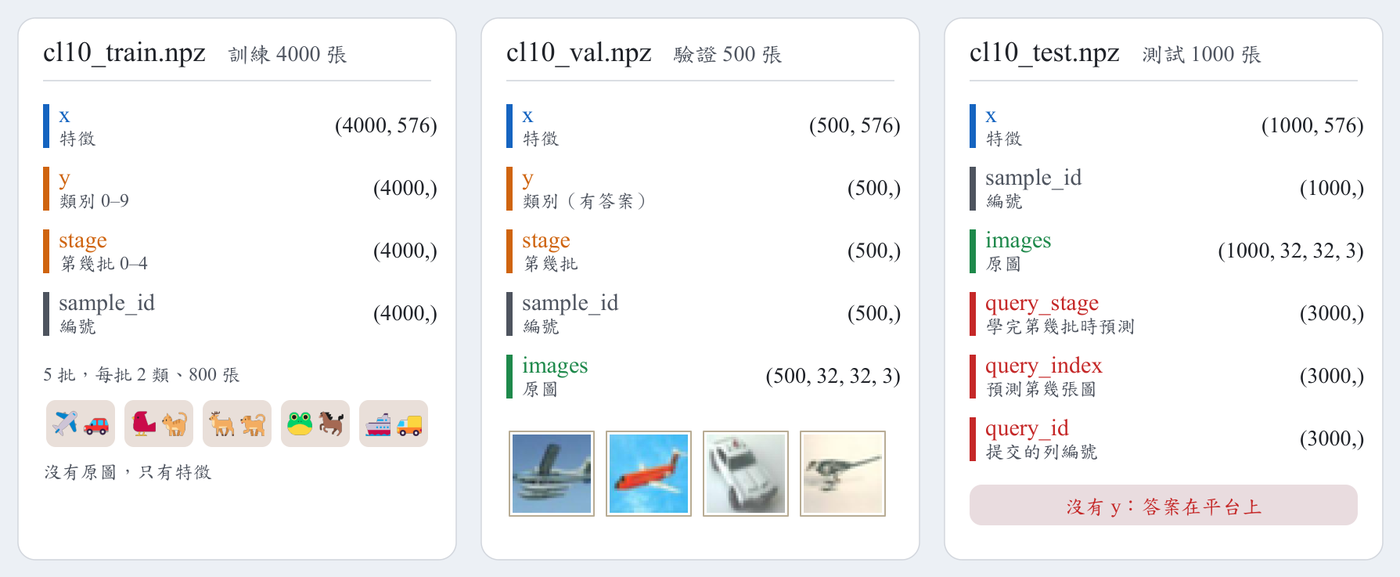

圖 1　三個資料檔的陣列與形狀。train 只有特徵；val、test 另外附 32×32 原圖。


In [ ]:
from pathlib import Path
import json, time, csv, urllib.request, copy
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
BASE='https://raw.githubusercontent.com/evan6007/tku-cl-2026/main/week10/'
for name in ['cl10_train.npz','cl10_val.npz','cl10_test.npz']:
    if not Path(name).exists():
        request=urllib.request.Request(BASE+name,headers={'User-Agent':'Mozilla/5.0'})
        with urllib.request.urlopen(request,timeout=120) as response:
            Path(name).write_bytes(response.read())
tr=np.load('cl10_train.npz'); va=np.load('cl10_val.npz'); te=np.load('cl10_test.npz')
assert 'y' not in te.files and tr['x'].shape==(4000,576)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)
def features(a): return F.normalize(torch.tensor(a,device=device,dtype=torch.float32),dim=1)
x,y=features(tr['x']),torch.tensor(tr['y'],device=device)
xv,yv=features(va['x']),torch.tensor(va['y'],device=device)
xt=features(te['x'])
print(device, torch.cuda.get_device_name() if device.type=='cuda' else 'CPU',len(x),len(xv),len(xt))

## 2. 設定、gate 與模型
預設 gate 為 576→32→256 sigmoid，只看第一階段 800 張訓練圖，500 次更新後凍結（這是範例做法，不是規則）。
對齊「減去首階段平均後、截斷至非負的特徵對 cosine」與連續 gate 的 cosine 相似度，另以平均活性靠近 0.25 為懲罰。此損失是本課簡化設定。
訓練 gate 不用不可微 top-k；分類時取 256 維中最大的 64 維，得到精確 25% 開啟率。
相似度對齊不保證未來類別具有分離路由，請實際觀察遮罩重疊。
`METHOD` 可選 `input_gate`、`all_open`、`random_fixed`。固定隨機組所有圖片共用同一個 64 維遮罩。

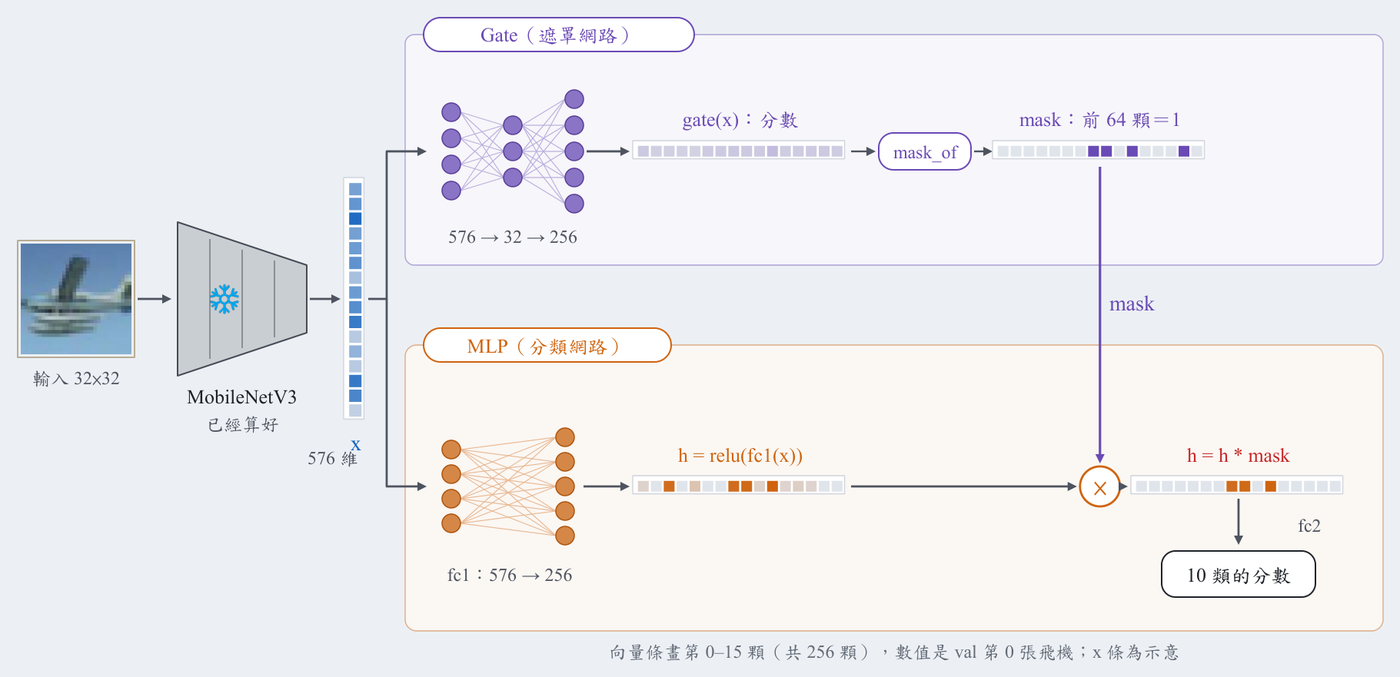

圖 2　Gate 給 256 顆隱藏神經元打分數，mask_of 取前 64 顆得到 mask；MLP 的隱藏層 h 乘上 mask，再經過 fc2。

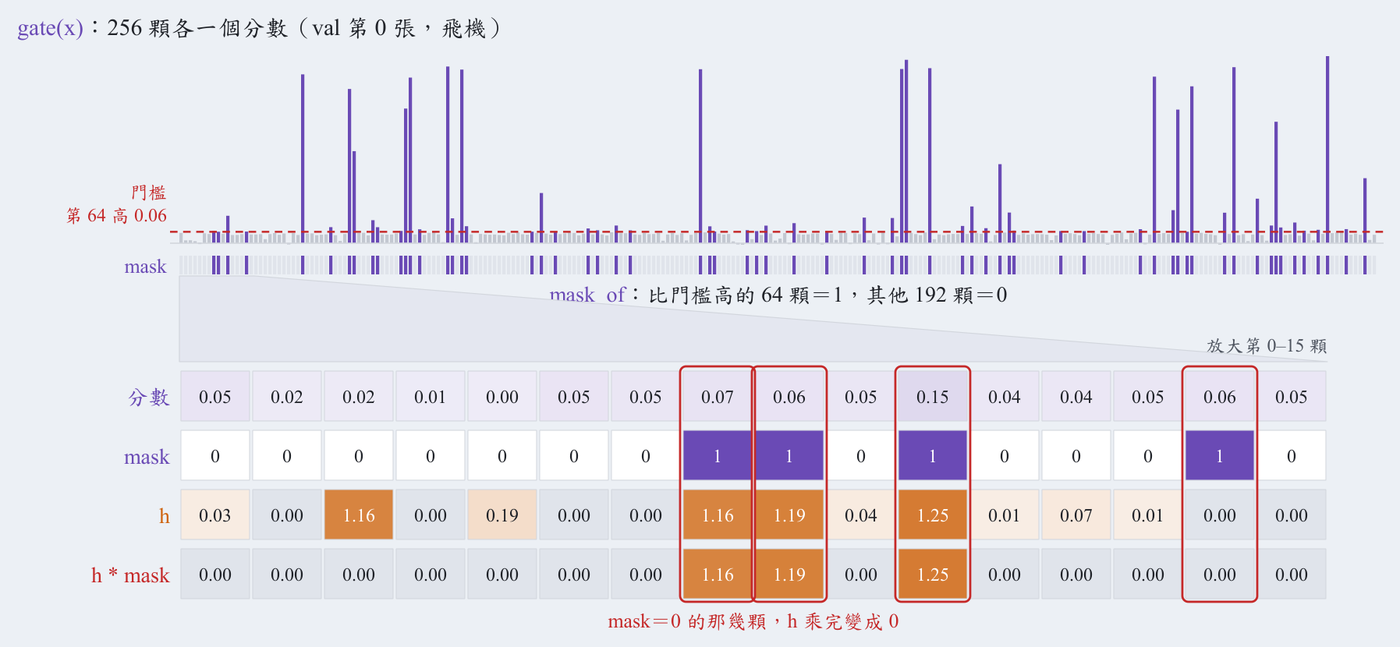

圖 3　val 第 0 張的 256 個 gate 分數與 mask；放大第 0–15 顆，mask＝0 的位置，h 乘完變成 0。數值是 SEED=115、METHOD=input_gate 實際跑出來的。


In [ ]:
METHOD='input_gate'
SEED=115
STEPS=200
BATCH=64
LR=.001
class Gate(nn.Sequential):
    def __init__(self): super().__init__(nn.Linear(576,32),nn.ReLU(),nn.Linear(32,256),nn.Sigmoid())
def mask_of(scores): return torch.zeros_like(scores).scatter_(1,scores.topk(64,dim=1).indices,1)
class MLP(nn.Module):
    def __init__(self):
        super().__init__(); self.fc1=nn.Linear(576,256); self.fc2=nn.Linear(256,10)
    def forward(self,x,mask):
        h=F.relu(self.fc1(x))
        # 本週核心：把此行換成 h 可觀察移除門控；正式比較也可切換 METHOD。
        h = h * mask
        return self.fc2(h)
assert METHOD in ['input_gate','all_open','random_fixed']

## 3. 訓練 gate 並逐階段訓練分類器
每階段只用當前訓練資料更新同一個 MLP。完成當前階段立即保存已見類別的測試預測，不回填過去階段。
訓練 loss 只計算目前兩類輸出 `logits[:, 2*stage:2*stage+2]`，標籤減 `2*stage`；測試仍在所有已見類別 argmax。訓練階段邊界已知，推論不提供每張圖片 task ID。
驗證僅計算指標。用同一 SEED 比較各 METHOD，初始權重、分類器抽樣順序及更新量相同。
重新執行本格會從頭開始；修改 METHOD 後由本格繼續即可。

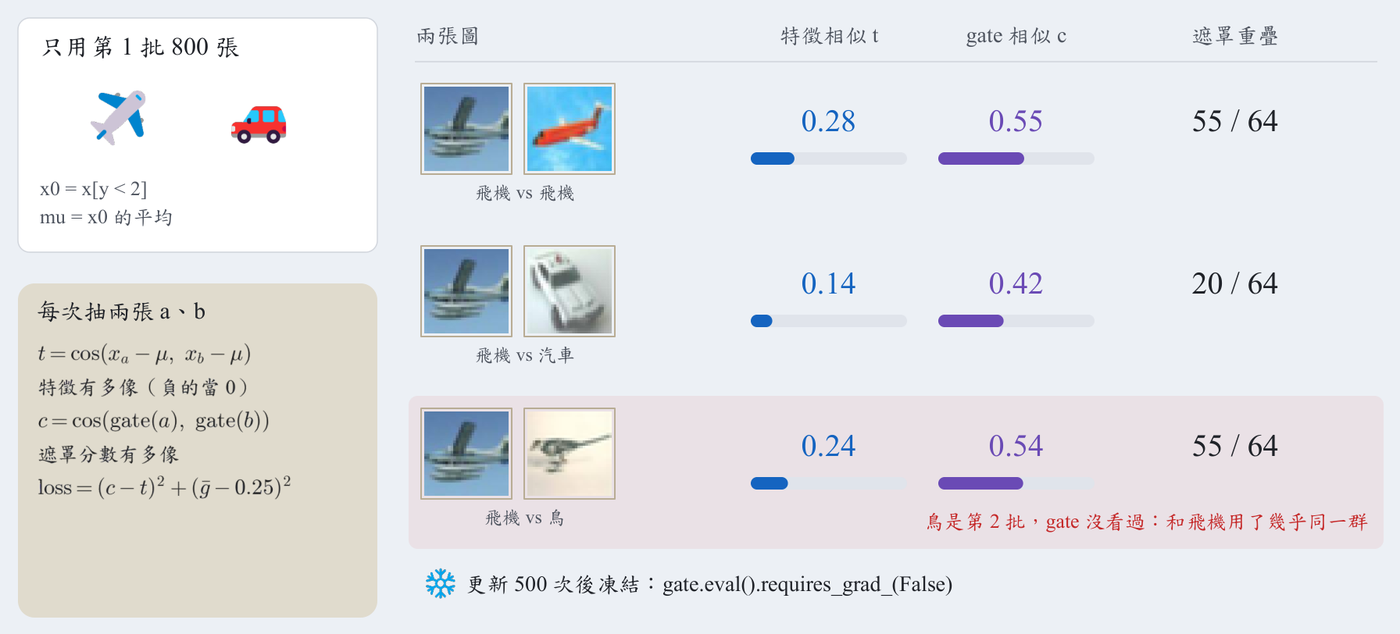

圖 4　gate 只用第 1 批訓練：兩張圖的特徵越像，gate 分數也要越像；更新 500 次後凍結。沒看過的鳥，和飛機用了幾乎同一群神經元。

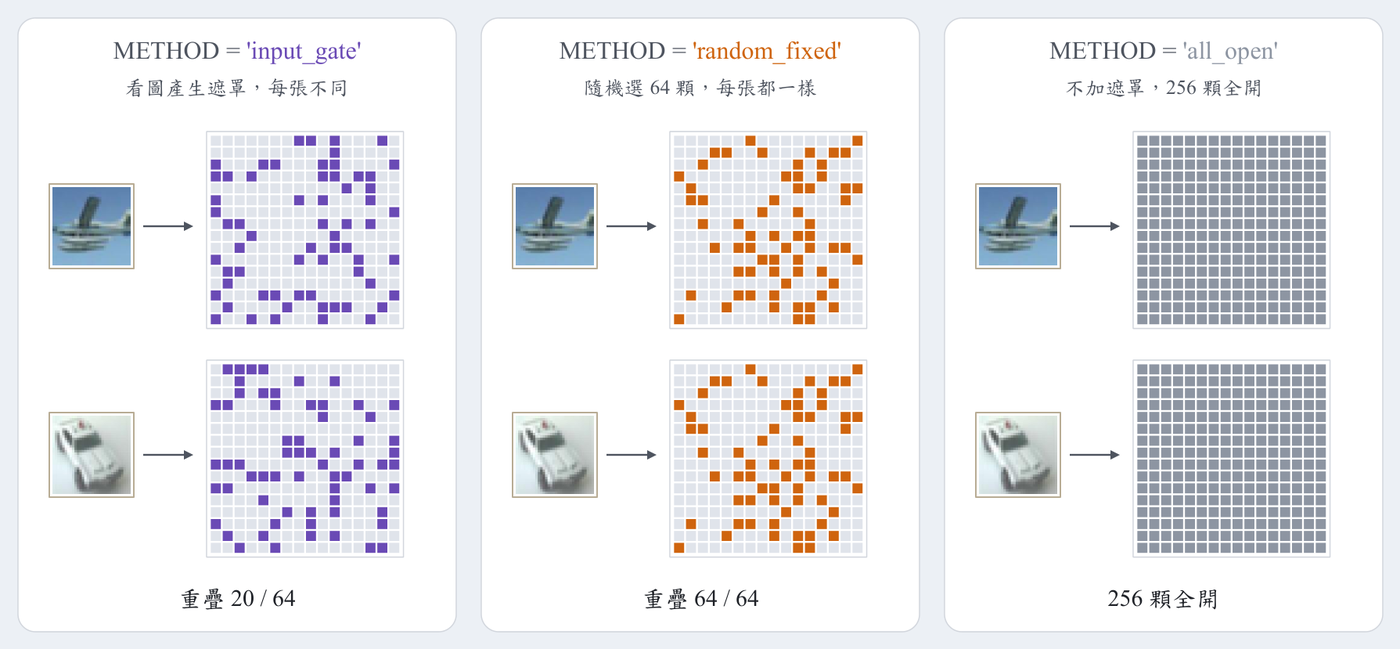

圖 5　三種 METHOD 的遮罩（256 顆排成 16×16，上：飛機，下：汽車）。

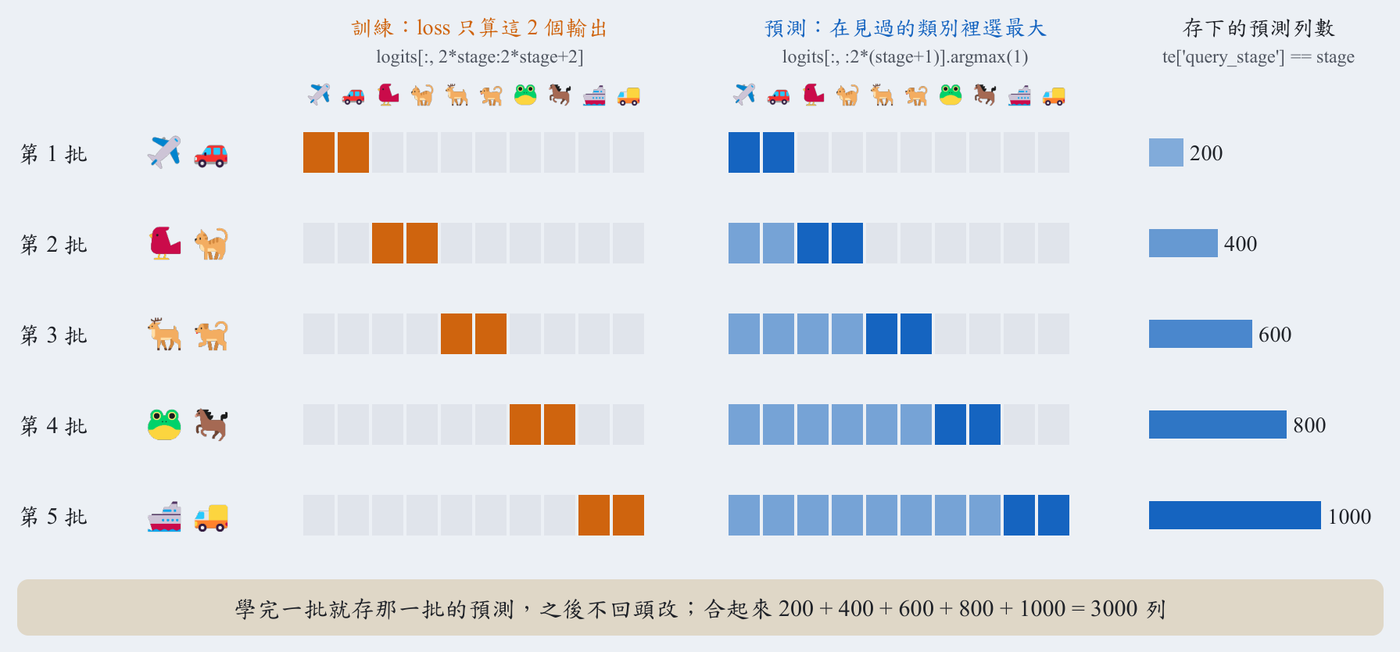

圖 6　每批的 loss 只算這一批 2 個輸出；預測時在見過的類別裡選最大，每批的預測立刻存下，合計 3000 列。


In [ ]:
start=time.perf_counter()
torch.manual_seed(SEED)
gate=Gate().to(device)
gopt=torch.optim.Adam(gate.parameters(),lr=.001)
x0=x[y<2]
mu=x0.mean(0,keepdim=True)
for step in range(500):
    a=x0[torch.randint(len(x0),(64,),device=device)]; b=x0[torch.randint(len(x0),(64,),device=device)]
    ga,gb=gate(a),gate(b)
    loss=F.mse_loss(F.cosine_similarity(ga,gb),F.cosine_similarity(a-mu,b-mu).clamp(min=0))+(torch.cat([ga,gb]).mean()-.25).square()
    gopt.zero_grad(); loss.backward(); gopt.step()
gate.eval().requires_grad_(False)
torch.manual_seed(SEED+1000)
model=MLP().to(device)
fixed=torch.zeros(1,256,device=device); fixed[:,torch.randperm(256,device=device)[:64]]=1
def getmask(z):
    if METHOD=='input_gate': return mask_of(gate(z))
    if METHOD=='random_fixed': return fixed
    return torch.ones(1,256,device=device)
with torch.no_grad(): mx,mv,mt=getmask(x),getmask(xv),getmask(xt)
opt=torch.optim.Adam(model.parameters(),lr=LR)
torch.manual_seed(SEED+2000)
matrix=np.full((5,5),np.nan); rows=[]; saved={}
for stage in range(5):
    ids=torch.where(y//2==stage)[0]
    model.train()
    for step in range(STEPS):
        ix=ids[torch.randint(len(ids),(BATCH,),device=device)]
        mask=mx[ix] if METHOD=='input_gate' else mx
        loss=F.cross_entropy(model(x[ix],mask)[:,2*stage:2*stage+2],y[ix]-2*stage)
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        vp=model(xv,mv)[:,:2*(stage+1)].argmax(1)
        tp=model(xt,mt)[:,:2*(stage+1)].argmax(1).cpu().numpy()
    ok=(vp==yv).float(); seen=yv<2*(stage+1); old=yv<2*stage; new=yv//2==stage
    for task in range(stage+1): matrix[task,stage]=float(ok[yv//2==task].mean())
    row=dict(stage=stage+1,seen=float(ok[seen].mean()),new=float(ok[new].mean()),old=float(ok[old].mean()) if stage else None)
    rows.append(row)
    for q in np.flatnonzero(te['query_stage']==stage):
        key=str(te['query_id'][q]); assert key not in saved
        saved[key]=int(tp[te['query_index'][q]])
    print(row)
if device.type=='cuda': torch.cuda.synchronize()
seconds=time.perf_counter()-start
print(f'gate + classifier + evaluation: {seconds:.2f} seconds')

## 4. 新／舊能力曲線與階段矩陣
矩陣列是被評估階段，欄是目前學完的階段。未見階段不評分。
新類別準確率低不等於遺忘；先確認某階段曾經學會，再看之後掉多少。

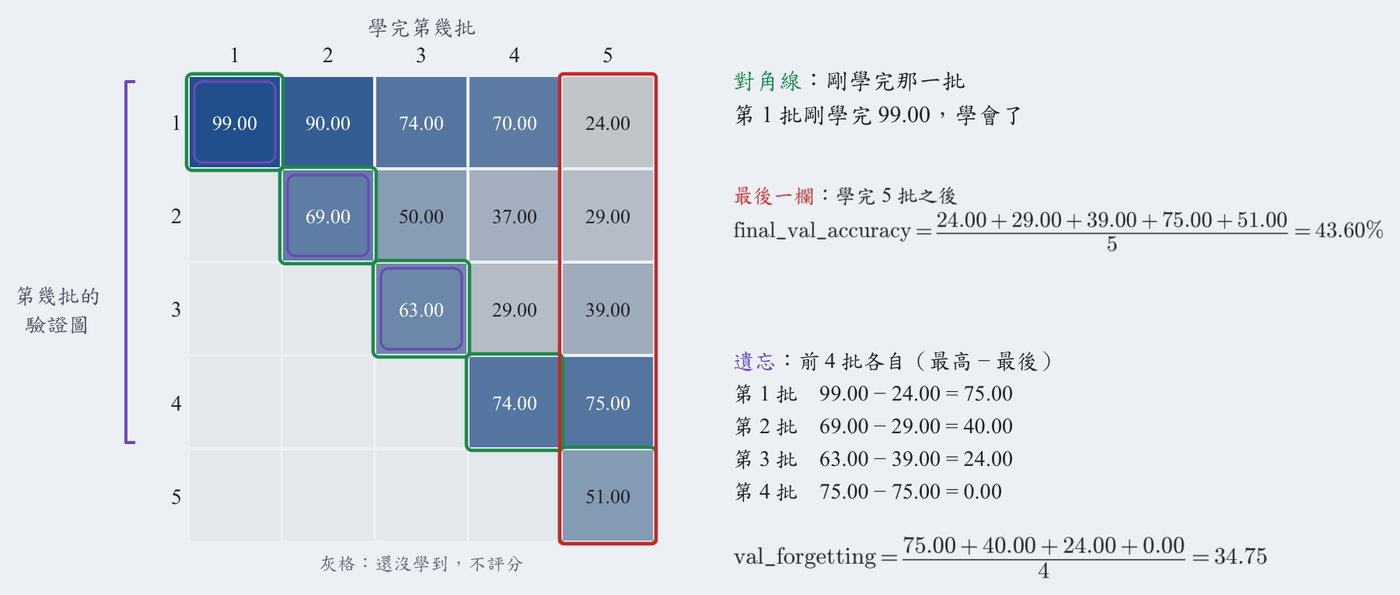

圖 7　階段矩陣怎麼讀：對角線＝剛學完，最後一欄平均＝最終準確率，前 4 批的最高 − 最後＝遺忘。


In [ ]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
for key in ['seen','new','old']:
    ax[0].plot(range(1,6),[100*r[key] if r[key] is not None else np.nan for r in rows],marker='o',label=key)
ax[0].set(xlabel='Learned stage',ylabel='Validation accuracy (%)',ylim=(0,100)); ax[0].legend()
im=ax[1].imshow(matrix*100,vmin=0,vmax=100); ax[1].set(xlabel='Learned stage',ylabel='Evaluated stage',xticks=range(5),xticklabels=range(1,6),yticks=range(5),yticklabels=range(1,6))
for i in range(5):
    for j in range(i,5): ax[1].text(j,i,f'{matrix[i,j]*100:.0f}',ha='center',color='white' if matrix[i,j]<.5 else 'black')
fig.colorbar(im,ax=ax[1]); plt.show()

## 5. 遺忘與路由重疊
最終平均準確率：五個階段最後準確率的平均。
遺忘：前四個階段「歷來最高準確率 − 最終準確率」的平均，單位百分點。
重疊率：兩個 64 維 mask 的交集數 ÷ 64；排除樣本自己與自己。

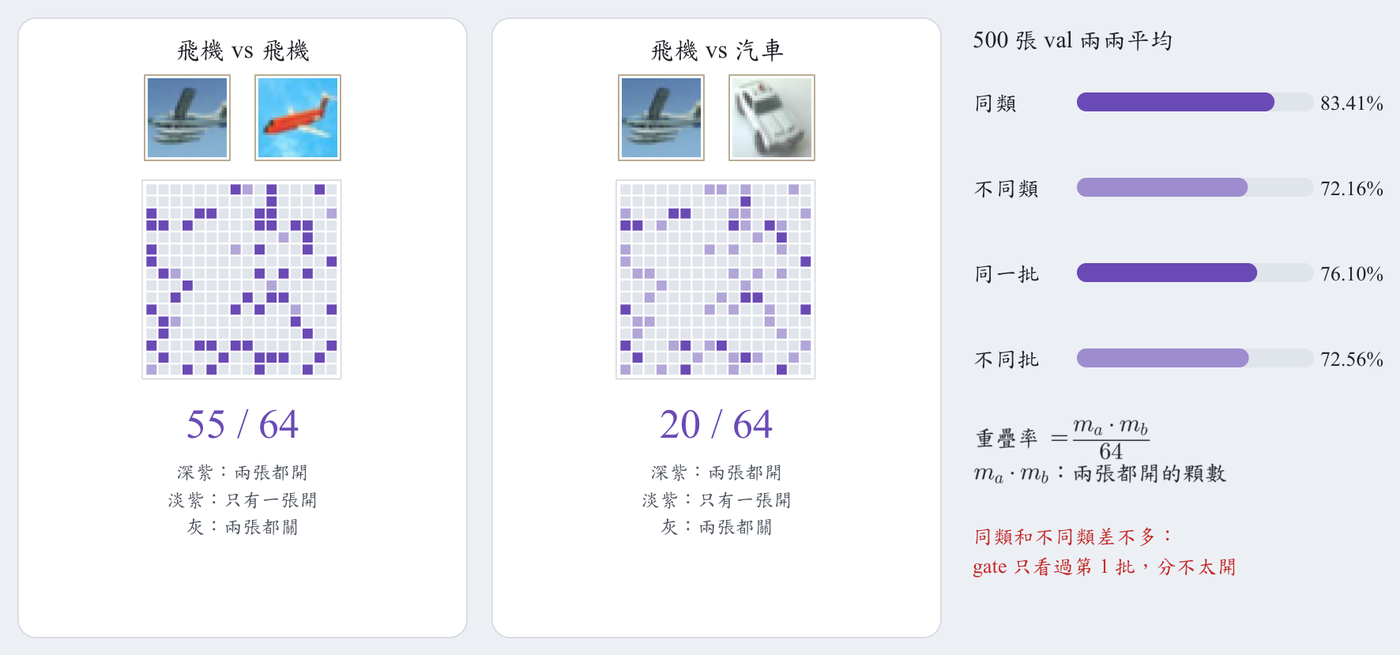

圖 8　兩張圖遮罩重疊的顆數，和 500 張 val 兩兩平均的重疊率。


In [ ]:
with torch.no_grad(): gm=mask_of(gate(xv)).cpu().numpy()
overlap=gm@gm.T; labels=va['y']; off=~np.eye(len(labels),dtype=bool)
same=labels[:,None]==labels[None,:]; same_stage=labels[:,None]//2==labels[None,:]//2
overlap_stats={}
for name,sel in [('same_class',same),('different_class',~same),('same_stage',same_stage),('different_stage',~same_stage)]:
    overlap_stats[name]=float(overlap[sel&off].mean()/64)
acc=float(matrix[:,-1].mean()); forgetting=float(np.mean(np.nanmax(matrix[:4],axis=1)-matrix[:4,-1]))
metrics=dict(method=METHOD,seed=SEED,final_val_accuracy=acc,val_forgetting=forgetting,seconds=seconds,
    stages=rows,matrix=[[None if np.isnan(v) else float(v) for v in row] for row in matrix],gate_overlap=overlap_stats,gate_open_fraction=float(gm.mean()))
print('Final val accuracy:',round(acc*100,2),'%; forgetting:',round(forgetting*100,2),'percentage points')
print(overlap_stats)
Path('metrics.json').write_text(json.dumps(metrics,indent=2))

## 6. 一張圖片經過 gate 與輸出提交檔
上傳 submission.csv（3000 列）與已執行 Notebook；Accuracy 計算全部階段即時預測的平均。
同一測試圖會在其出現後的階段重複評估；不可用最後模型覆寫較早階段預測。

In [ ]:
i=0
with torch.no_grad():
    scores=gate(xv[i:i+1]); mask=mask_of(scores); h=F.relu(model.fc1(xv[i:i+1]))
fig,ax=plt.subplots(1,3,figsize=(12,3))
ax[0].imshow(va['images'][i]); ax[0].set_title(f'Validation label={int(yv[i])}'); ax[0].axis('off')
ax[1].bar(range(256),scores[0].cpu()); ax[1].set_title('Gate scores')
ax[2].bar(range(256),(h*mask)[0].cpu()); ax[2].set_title('h * mask'); plt.show()
print('h[:16]',h[0,:16].cpu().tolist()); print('(h*mask)[:16]',(h*mask)[0,:16].cpu().tolist())
assert len(saved)==3000
with open('submission.csv','w',newline='') as f:
    writer=csv.writer(f); writer.writerow(['id','label'])
    writer.writerows((str(key),saved[str(key)]) for key in te['query_id'])
torch.save({'model':model.state_dict(),'gate':gate.state_dict(),'method':METHOD,'seed':SEED,'fixed_mask':fixed.cpu()},'checkpoint.pt')
print('Saved submission.csv, metrics.json, checkpoint.pt')

## 7. 比較與五分鐘報告
1. 固定 SEED，分別執行 all_open、input_gate、random_fixed，另存各次 metrics.json。
2. 哪一組新類別學得最好？舊類別掉最多？門控是否犧牲了新類別容量？
3. 同類與異類 mask 重疊是否不同？同階段與異階段呢？
4. 為什麼只看首階段的 gate 可能無法路由之後的新類別？

教師三種子結果：全開最終測試準確率 55.03%、首階段 gate 48.30%、固定隨機 46.03%。另有看過全部五批 train 的 gate 54.07%，它使用未來資料，僅作不同資訊條件的教師參考，不允許參賽。這些是 res10.json 三種子的最終測試平均，不是本 Notebook 單種子的驗證分數，也不是 3000 列競賽 Accuracy。此設定經教學篩選，沒有獨立驗證集選參，不能當作無偏方法排名。
本版使用 256 隱藏單元、64 顆開啟、gate 500 次與分類器每階段 200 次更新；實際秒數見執行輸出。Colab T4 尚未實測，不保證相同時間。

題目規則只有三條：
1. 模型輸入只用提供的 576 維特徵；val／test 附的原圖只供觀察，不進模型。特徵後面接什麼都可以，包括 MobileNetV3-Small 的 ImageNet 預訓練分類頭。
2. 依序學：第 k 批只用第 k 批 train 更新（任何網路都一樣，包括 gate），不回看舊資料，也不用 val 訓練；學完一批立即保存預測，不回填。
3. 不將任務 id、query_stage、sample_id 當模型輸入。

其餘都可以自己決定：方法、gate 的結構與何時訓練、隱藏層大小、開啟顆數、學習率、loss。本 Notebook 的做法（gate 只用第 1 批訓練後凍結、每批 200 次更新）只是預設範例。

參考：[Shi et al., Nature Communications 2025](https://www.nature.com/articles/s41467-025-56405-9) · [作者程式](https://github.com/qqish/CH-HNN)